In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import BaggingClassifier, AdaBoostClassifier, VotingClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')


In [ ]:

import os

files_list = os.listdir('/content')
print(files_list)

['.config', 'data_ecommerce_customer_churn.csv', 'sample_data']


In [ ]:

file_name = [f for f in os.listdir('/content') if f.startswith('data_ecommerce_customer_churn')][0]

if file_name.endswith('.xlsx'):
    df = pd.read_excel('/content/' + file_name)
elif file_name.endswith('.csv'):
    df = pd.read_csv('/content/' + file_name)

print(df.shape)
df.head()

(3941, 11)


,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
0,15.0,29.0,4,Laptop & Accessory,3,Single,2,0,7.0,143.32,0
1,7.0,25.0,4,Mobile,1,Married,2,0,7.0,129.29,0
2,27.0,13.0,3,Laptop & Accessory,1,Married,5,0,7.0,168.54,0
3,20.0,25.0,4,Fashion,3,Divorced,7,0,NaN,230.27,0
4,30.0,15.0,4,Others,4,Single,8,0,8.0,322.17,0


In [ ]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3941 entries, 0 to 3940
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Tenure                    3747 non-null   float64
 1   WarehouseToHome           3772 non-null   float64
 2   NumberOfDeviceRegistered  3941 non-null   int64  
 3   PreferedOrderCat          3941 non-null   object 
 4   SatisfactionScore         3941 non-null   int64  
 5   MaritalStatus             3941 non-null   object 
 6   NumberOfAddress           3941 non-null   int64  
 7   Complain                  3941 non-null   int64  
 8   DaySinceLastOrder         3728 non-null   float64
 9   CashbackAmount            3941 non-null   float64
 10  Churn                     3941 non-null   int64  
dtypes: float64(4), int64(5), object(2)
memory usage: 338.8+ KB


In [ ]:

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nStatistical Summary:")
display(df.describe(include='all'))


Dataset Shape: (3941, 11)

Column Names:
['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'DaySinceLastOrder', 'CashbackAmount', 'Churn']

Statistical Summary:


,Tenure,WarehouseToHome,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,DaySinceLastOrder,CashbackAmount,Churn
count,3747.000000,3772.000000,3941.000000,3941,3941.000000,3941,3941.000000,3941.000000,3728.000000,3941.000000,3941.000000
unique,NaN,NaN,NaN,6,NaN,3,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,Laptop & Accessory,NaN,Married,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,1458,NaN,2055,NaN,NaN,NaN,NaN,NaN
mean,10.081398,15.650583,3.679269,NaN,3.088302,NaN,4.237757,0.282416,4.531652,176.707419,0.171023
std,8.498864,8.452301,1.013938,NaN,1.381832,NaN,2.626699,0.450232,3.667648,48.791784,0.376576
min,0.000000,5.000000,1.000000,NaN,1.000000,NaN,1.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,9.000000,3.000000,NaN,2.000000,NaN,2.000000,0.000000,2.000000,145.700000,0.000000
50%,9.000000,14.000000,4.000000,NaN,3.000000,NaN,3.000000,0.000000,3.000000,163.340000,0.000000
75%,16.000000,21.000000,4.000000,NaN,4.000000,NaN,6.000000,1.000000,7.000000,195.250000,0.000000


In [ ]:

print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Rows:", df.duplicated().sum())


Missing Values:
Tenure                      194
WarehouseToHome             169
NumberOfDeviceRegistered      0
PreferedOrderCat              0
SatisfactionScore             0
MaritalStatus                 0
NumberOfAddress               0
Complain                      0
DaySinceLastOrder           213
CashbackAmount                0
Churn                         0
dtype: int64

Total Missing Values: 576

Duplicate Rows: 671


Churn
0    3267
1     674
Name: count, dtype: int64

Churn Percentage:
Churn
0    82.897742
1    17.102258
Name: proportion, dtype: float64


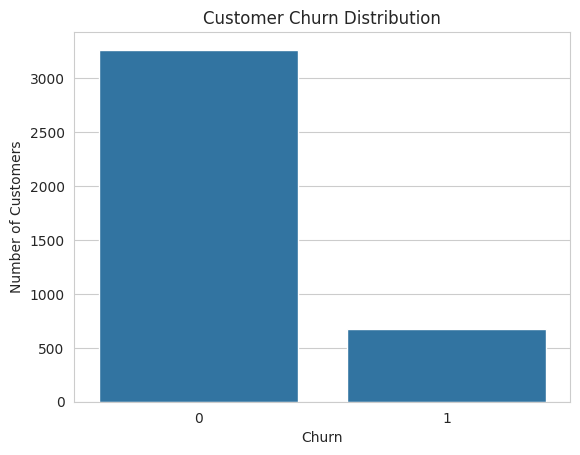

In [ ]:

print(df['Churn'].value_counts())

print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)

sns.countplot(data=df, x='Churn')
plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()


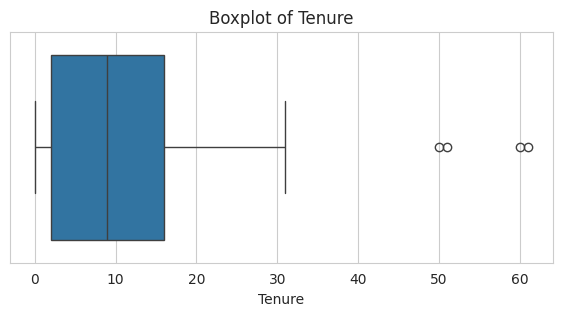

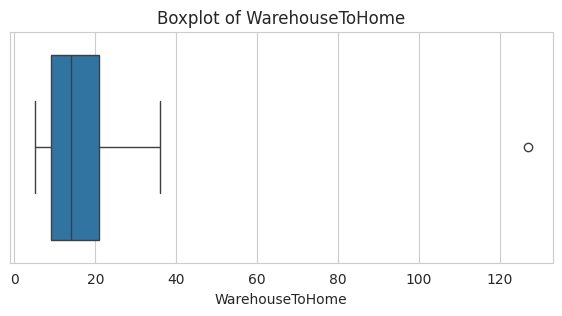

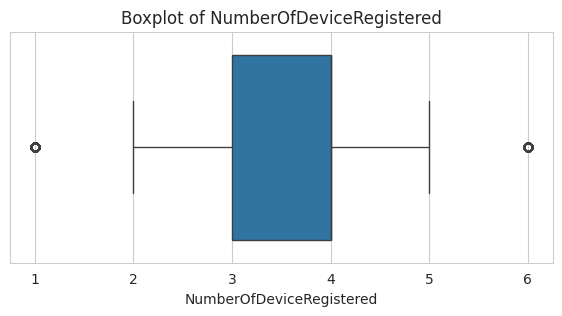

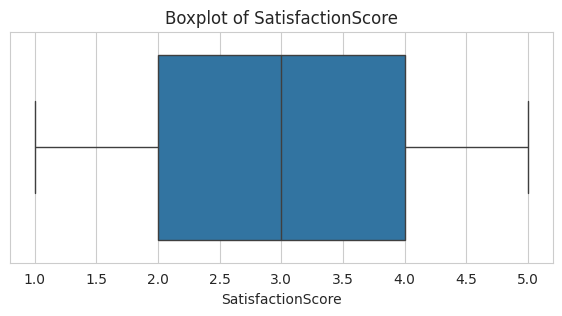

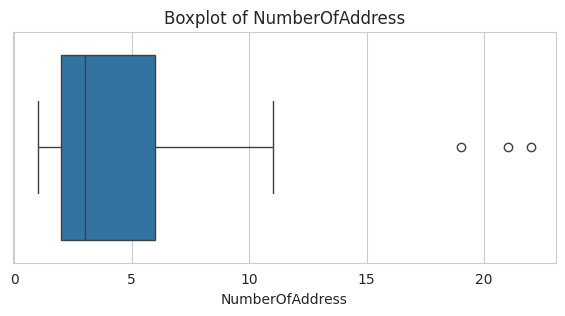

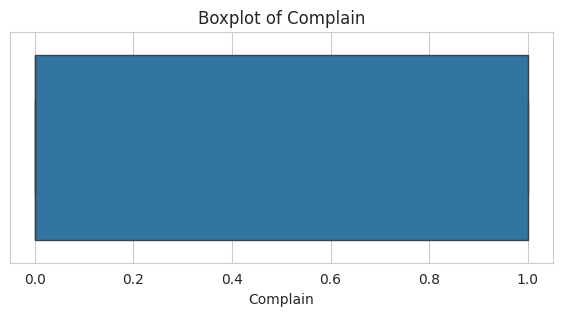

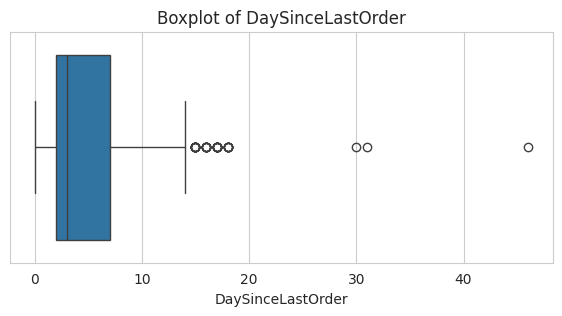

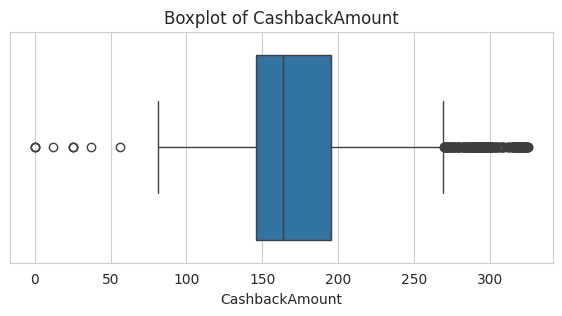

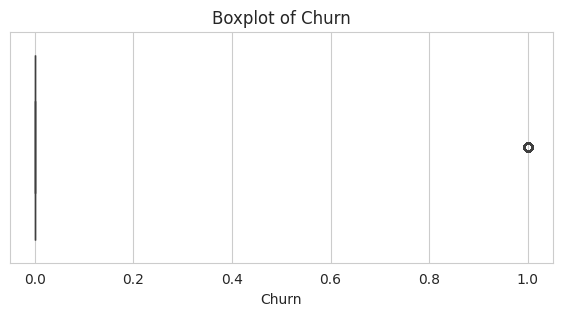

In [ ]:

num_cols = df.select_dtypes(include=np.number).columns.tolist()

for col in num_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()


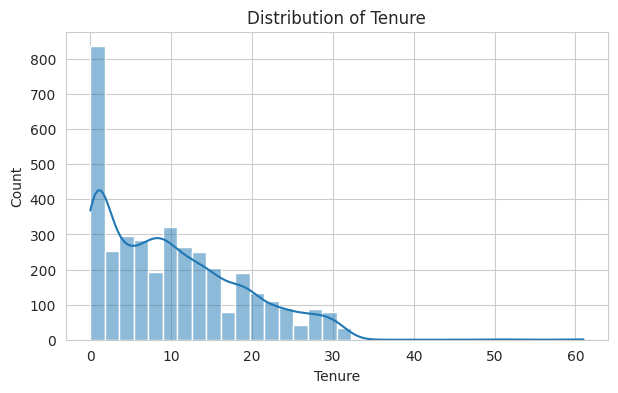

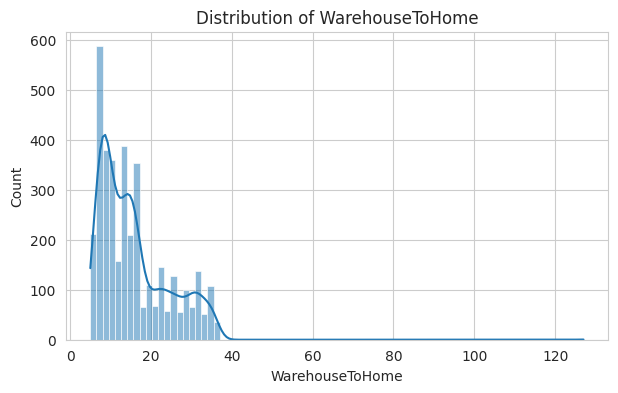

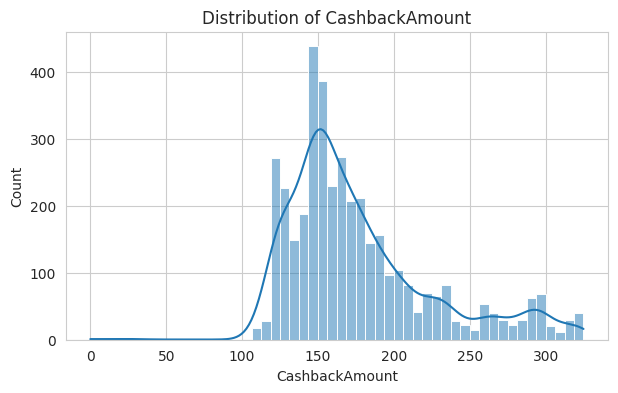

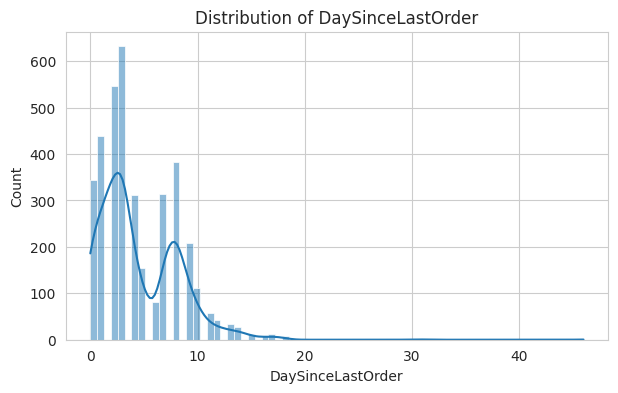

In [ ]:

numerical_features = [
    'Tenure',
    'WarehouseToHome',
    'CashbackAmount',
    'DaySinceLastOrder'
]

for col in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.show()


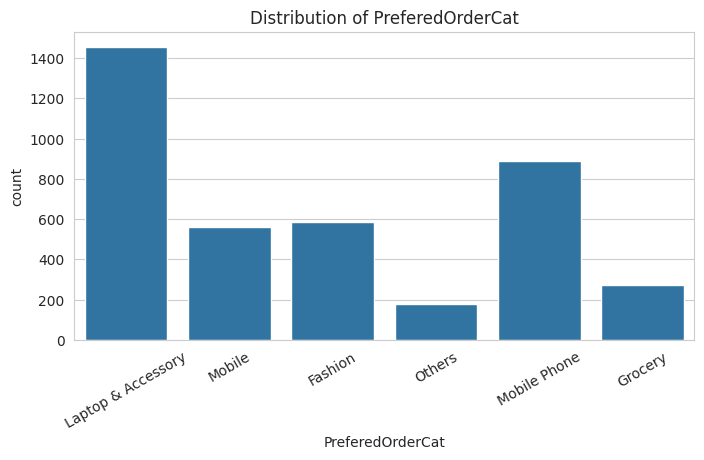

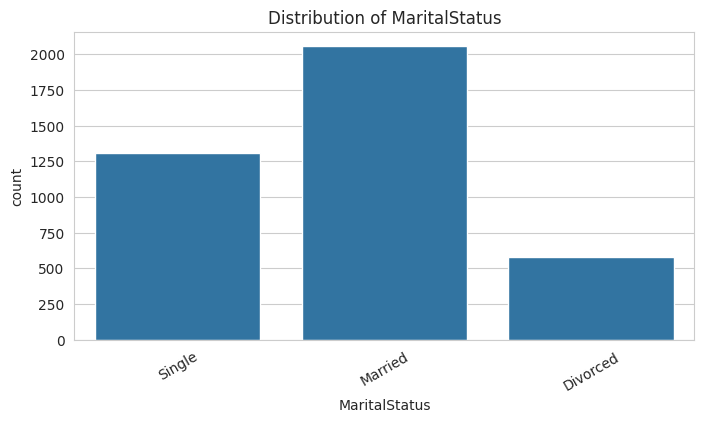

In [ ]:

categorical_features = [
    'PreferedOrderCat',
    'MaritalStatus'
]

for col in categorical_features:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=df, x=col)
    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=30)
    plt.show()


In [ ]:

print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nChurn Distribution:")
print(df['Churn'].value_counts())

print("\nChurn Percentage:")
print(df['Churn'].value_counts(normalize=True) * 100)


Missing Values:
Tenure                      194
WarehouseToHome             169
NumberOfDeviceRegistered      0
PreferedOrderCat              0
SatisfactionScore             0
MaritalStatus                 0
NumberOfAddress               0
Complain                      0
DaySinceLastOrder           213
CashbackAmount                0
Churn                         0
dtype: int64

Duplicate Rows:
671

Churn Distribution:
Churn
0    3267
1     674
Name: count, dtype: int64

Churn Percentage:
Churn
0    82.897742
1    17.102258
Name: proportion, dtype: float64


In [16]:

#Data Inspection Results

#The dataset contains 3,941 rows and 11 columns.

#Three numerical features contain missing values: Tenure, WarehouseToHome, and DaySinceLastOrder.

##The target variable Churn is imbalanced:
#- 0 (Retained Customers): 82.90%
#- 1 (Churned Customers): 17.10%
#The missing values will be handled using median imputation inside the preprocessing pipeline


In [ ]:

num_cols = df.select_dtypes(include=np.number).drop(columns=['Churn']).columns.tolist()

cat_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical Columns:")
print(num_cols)

print("\nCategorical Columns:")
print(cat_cols)


Numerical Columns:
['Tenure', 'WarehouseToHome', 'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress', 'Complain', 'DaySinceLastOrder', 'CashbackAmount']

Categorical Columns:
['PreferedOrderCat', 'MaritalStatus']


In [ ]:

X = df.drop('Churn', axis=1)
y = df['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True) * 100)


Training Features Shape: (3152, 10)
Testing Features Shape: (789, 10)

Training Target Distribution:
Churn
0    82.899746
1    17.100254
Name: proportion, dtype: float64

Testing Target Distribution:
Churn
0    82.889734
1    17.110266
Name: proportion, dtype: float64


In [17]:

#Why is setting random_state essential?
#Setting random_state ensures reproducibility when splitting the dataset. It guarantees that the same training and testing samples are selected every time the code is executed.

#This makes model evaluation consistent and allows fair comparison between different machine learning models.


In [ ]:

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', MinMaxScaler())
])

num_pipeline.fit(X_train[num_cols])

print("Learned Medians:")
print(num_pipeline.named_steps['imputer'].statistics_)


Learned Medians:
[  9.    14.     4.     3.     3.     0.     3.   162.72]


In [ ]:

### Attribute Inspection

# The SimpleImputer uses the `statistics_` attribute to store the learned imputation values.

#It uses this attribute instead of `median_` because SimpleImputer supports multiple imputation strategies, such as mean, median, most_frequent, and constant. Therefore, statistics_ provides a unified attribute for storing the learned values regardless of the selected strategy.


In [19]:
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

cat_transformed = cat_pipeline.fit_transform(X_train[cat_cols])

print("Categorical Output Type:")
print(type(cat_transformed))

print("\nCategorical Output Shape:")
print(cat_transformed.shape)

Categorical Output Type:
<class 'scipy.sparse._csr.csr_matrix'>

Categorical Output Shape:
(3152, 9)


In [ ]:
#Sparse Matrix Inspection

#The OneHotEncoder returned a SciPy CSR Sparse Matrix instead of a dense NumPy array.

#Output Type:scipy.sparse._csr.csr_matrix

#Output Shape:(3152, 9)

#Scikit-learn returns a sparse matrix by default because One-Hot Encoding produces many zero values.
#Storing only non-zero values reduces memory consumption and improves computational efficiency, especially when dealing with high-dimensional categorical data.

In [20]:

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

print("Training Data Shape:", X_train_prepared.shape)
print("Testing Data Shape:", X_test_prepared.shape)


Training Data Shape: (3152, 17)
Testing Data Shape: (789, 17)


In [21]:

master_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

master_pipeline.fit(X_train, y_train)

print("Master Pipeline Training Score:",
      master_pipeline.score(X_train, y_train))

print("Master Pipeline Testing Score:",
      master_pipeline.score(X_test, y_test))


Master Pipeline Training Score: 0.8861040609137056
Master Pipeline Testing Score: 0.8719898605830165


In [ ]:
#Execution Flow of pipeline.fit(X_train, y_train)

#When `pipeline.fit(X_train, y_train)` is executed, scikit-learn performs the following steps internally:

#1. **Transformers Execution:** The preprocessing steps are fitted on the training data. The numerical pipeline learns the median values and scaling parameters, while the categorical pipeline learns the most frequent values and category encoding.

#2. **Data Transformation:** The fitted transformers transform the training features into a numerical representation using imputation, scaling, and One-Hot Encoding.

#3. **Final Estimator Execution:** The transformed training data and target variable (y_train) are passed to the final classifier, which learns the relationship between the input features and the target.

#Difference between Transformers and Final Estimator:**

#- Transformers learn how to modify the input features and transform them into a suitable format.
#- The final estimator uses the transformed features and target labels to train the predictive model.

#This approach ensures consistent preprocessing and helps prevent data leakage when combined with proper train/test splitting.

In [22]:

shallow_tree = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(max_depth=1, random_state=42))
])

shallow_tree.fit(X_train, y_train)

complex_tree = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

complex_tree.fit(X_train, y_train)

print("Shallow Decision Tree:")
print("Training Score:", shallow_tree.score(X_train, y_train))
print("Testing Score:", shallow_tree.score(X_test, y_test))

print("\nComplex Decision Tree:")
print("Training Score:", complex_tree.score(X_train, y_train))
print("Testing Score:", complex_tree.score(X_test, y_test))


Shallow Decision Tree:
Training Score: 0.8451776649746193
Testing Score: 0.8377693282636248

Complex Decision Tree:
Training Score: 1.0
Testing Score: 0.9290240811153359


In [ ]:
#Bias-Variance Tradeoff

#1. What happens to bias and variance as model complexity increases?**

#As model complexity increases, bias generally decreases because the model becomes more flexible and can capture complex patterns in the training data. However, variance generally increases because the model becomes more sensitive to small changes in the training data.

#- High Bias: The model is too simple and tends to underfit.
#- High Variance: The model is too complex and may overfit the training data.

#2. Why does increasing model complexity resolve underfitting, while adding more training examples does not?**

#When a model underfits, it lacks sufficient complexity to learn the underlying patterns in the data. Increasing model complexity allows it to capture more relationships and reduce bias.

#Adding more training examples does not necessarily solve underfitting because the model still has limited learning capacity. Therefore, increasing model complexity is a more appropriate solution when the main problem is high bias.

In [23]:

from sklearn.base import clone

log_l2 = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', LogisticRegression(
        penalty='l2',
        solver='saga',
        max_iter=2000,
        random_state=42
    ))
])

log_l1 = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', LogisticRegression(
        penalty='l1',
        solver='saga',
        max_iter=2000,
        random_state=42
    ))
])


log_elastic = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', LogisticRegression(
        penalty='elasticnet',
        l1_ratio=0.5,
        solver='saga',
        max_iter=2000,
        random_state=42
    ))
])

log_l2.fit(X_train, y_train)
log_l1.fit(X_train, y_train)
log_elastic.fit(X_train, y_train)

models = {
    'L2 Regularization': log_l2,
    'L1 Regularization': log_l1,
    'Elastic Net': log_elastic
}

for name, model in models.items():
    print("\n", name)
    print("Training Accuracy:", model.score(X_train, y_train))
    print("Testing Accuracy:", model.score(X_test, y_test))



 L2 Regularization
Training Accuracy: 0.8854695431472082
Testing Accuracy: 0.8719898605830165

 L1 Regularization
Training Accuracy: 0.886738578680203
Testing Accuracy: 0.8745247148288974

 Elastic Net
Training Accuracy: 0.8864213197969543
Testing Accuracy: 0.8732572877059569


In [ ]:
#Regularization & Shrinkage in Logistic Regression

#Three Logistic Regression models were trained using different regularization techniques: L1, L2, and Elastic Net.

#Results:

#| Regularization | Training Accuracy | Testing Accuracy |
#| L1 | 88.67% | 87.45% |
#| L2 | 88.55% | 87.20% |
#| Elastic Net | 88.64% | 87.33% |

#Analysis:

#L1 (Lasso):** Uses absolute values of coefficients and can shrink some coefficients to exactly zero, which helps with feature selection.
#L2 (Ridge):** Uses squared coefficients and reduces their magnitude without usually making them exactly zero.
#Elastic Net:** Combines L1 and L2 penalties, providing both coefficient shrinkage and feature selection.

#Conclusion:

#L1 achieved the highest testing accuracy (87.45%), followed by Elastic Net (87.33%) and L2 (87.20%). However, the differences are small, so additional evaluation metrics are needed for a more reliable comparison.

In [24]:

from sklearn.ensemble import BaggingClassifier

bagging_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        bootstrap=True,
        oob_score=True,
        n_jobs=-1,
        random_state=42
    ))
])

bagging_model.fit(X_train, y_train)

print("Bagging Training Accuracy:",
      bagging_model.score(X_train, y_train))

print("Bagging Testing Accuracy:",
      bagging_model.score(X_test, y_test))

print("OOB Score:",
      bagging_model.named_steps['classifier'].oob_score_)


Bagging Training Accuracy: 1.0
Bagging Testing Accuracy: 0.9480354879594424
OOB Score: 0.9375


In [ ]:
#Bagging vs. Pasting & Out-of-Bag Evaluation

#1. What does n_jobs=-1 mean?

#Setting `n_jobs=-1` instructs scikit-learn to use all available CPU cores to perform computations in parallel, which can reduce training time.

#2. Which ensemble technique is used when bootstrap=False?**

#When `bootstrap=False`, the BaggingClassifier uses **Pasting**. It selects random subsets of the training data without replacement.

#3. What is the main advantage of Out-of-Bag (OOB) evaluation?**

#OOB evaluation provides an estimate of model performance using training instances that were not selected in the bootstrap sample for each individual estimator. Its main advantage is that it provides an internal validation estimate without requiring a separate validation set.

#Results:

#- Bagging Training Accuracy: 100%
#- Bagging Testing Accuracy: 94.80%
#- OOB Score: 93.75%

#The OOB score is close to the testing accuracy, indicating that the internal OOB estimate is reasonably consistent with the model's test performance.

In [26]:

pasting_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        bootstrap=False,
        n_jobs=-1,
        random_state=42
    ))
])

pasting_model.fit(X_train, y_train)

print("Pasting Training Accuracy:",
      pasting_model.score(X_train, y_train))

print("Pasting Testing Accuracy:",
      pasting_model.score(X_test, y_test))


Pasting Training Accuracy: 1.0
Pasting Testing Accuracy: 0.9328263624841572


In [ ]:
#Bagging vs. Pasting Comparison

#Both ensemble models achieved 100% training accuracy.

#However, Bagging achieved a higher testing accuracy of 94.80%, compared to 93.28% for Pasting.

#Key Differences:**

#- Bagging uses sampling with replacement (bootstrap=True).
#- Pasting uses sampling without replacement (bootstrap=False).
#- Bagging supports Out-of-Bag evaluation because some training instances are excluded from each bootstrap sample.
#- Pasting does not provide the standard OOB evaluation used by Bagging.

#Conclusion:

#Bagging performed better than Pasting on the test dataset, with an improvement of approximately 1.52 percentage points in testing accuracy.

In [27]:

from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

adaboost_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=1,
            random_state=42
        ),
        n_estimators=100,
        learning_rate=0.5,
        random_state=42
    ))
])


adaboost_model.fit(X_train, y_train)

y_pred_ada = adaboost_model.predict(X_test)

print("AdaBoost Evaluation")

print("Accuracy:", accuracy_score(y_test, y_pred_ada))
print("Precision:", precision_score(y_test, y_pred_ada, zero_division=0))
print("Recall:", recall_score(y_test, y_pred_ada, zero_division=0))
print("F1-Score:", f1_score(y_test, y_pred_ada, zero_division=0))


AdaBoost Evaluation
Accuracy: 0.8656527249683144
Precision: 0.6883116883116883
Recall: 0.3925925925925926
F1-Score: 0.5


In [ ]:
#AdaBoost – Weight Updates

#In AdaBoost, the weights of misclassified training instances are increased from one iteration to the next, while correctly classified instances receive relatively less emphasis.

#This happens because AdaBoost focuses more on the difficult instances that previous weak learners failed to classify correctly.

#The goal is to make subsequent weak learners pay more attention to previous classification errors and improve the overall ensemble performance.

In [28]:

from sklearn.ensemble import VotingClassifier, RandomForestClassifier
from sklearn.svm import SVC

hard_voting_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', VotingClassifier(
        estimators=[
            ('lr', LogisticRegression(max_iter=2000)),
            ('rf', RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )),
            ('svc', SVC(probability=True, random_state=42))
        ],
        voting='hard',
        n_jobs=-1
    ))
])

hard_voting_model.fit(X_train, y_train)

y_pred_hard = hard_voting_model.predict(X_test)


print("Hard Voting Accuracy:",
      accuracy_score(y_test, y_pred_hard))

print("Hard Voting Precision:",
      precision_score(y_test, y_pred_hard, zero_division=0))

print("Hard Voting Recall:",
      recall_score(y_test, y_pred_hard, zero_division=0))

print("Hard Voting F1-Score:",
      f1_score(y_test, y_pred_hard, zero_division=0))


Hard Voting Accuracy: 0.8808618504435995
Hard Voting Precision: 0.8360655737704918
Hard Voting Recall: 0.37777777777777777
Hard Voting F1-Score: 0.5204081632653061


In [29]:

soft_voting_model = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('classifier', VotingClassifier(
        estimators=[
            ('lr', LogisticRegression(max_iter=2000)),
            ('rf', RandomForestClassifier(
                n_estimators=100,
                random_state=42,
                n_jobs=-1
            )),
            ('svc', SVC(probability=True, random_state=42))
        ],
        voting='soft',
        n_jobs=-1
    ))
])

soft_voting_model.fit(X_train, y_train)

y_pred_soft = soft_voting_model.predict(X_test)

print("Soft Voting Accuracy:",
      accuracy_score(y_test, y_pred_soft))

print("Soft Voting Precision:",
      precision_score(y_test, y_pred_soft, zero_division=0))

print("Soft Voting Recall:",
      recall_score(y_test, y_pred_soft, zero_division=0))

print("Soft Voting F1-Score:",
      f1_score(y_test, y_pred_soft, zero_division=0))


Soft Voting Accuracy: 0.8897338403041825
Soft Voting Precision: 0.8333333333333334
Soft Voting Recall: 0.4444444444444444
Soft Voting F1-Score: 0.5797101449275363


In [ ]:

#Two Voting Classifiers were trained using Logistic Regression, Random Forest, and SVC with probability=True.

#Results:

#| Metric | Hard Voting | Soft Voting |
#|---|---:|---:|
#| Accuracy | 88.09% | 88.97% |
#| Precision | 83.61% | 83.33% |
#| Recall | 37.78% | 44.44% |
#| F1-Score | 52.04% | 57.97% |

#Hard Voting:

#Hard Voting predicts the class selected by the majority of the individual classifiers.

#Soft Voting:

#Soft Voting calculates the average predicted probabilities from all classifiers and selects the class with the highest average probability.

#Conclusion:

#Soft Voting achieved better Accuracy, Recall, and F1-Score than Hard Voting, while Hard Voting achieved slightly higher Precision.

#Therefore, Soft Voting performed better overall in this experiment, especially in terms of balancing Precision and Recall.